In [37]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import scipy.stats as stats
import re
from scipy.optimize import curve_fit
import os

import matplotlib


import sys
sys.path.insert(0, "../../")
import builtins
    
builtins.NAMING = "new"

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *
%config InlineBackend.figure_format ='retina'


slope=0.000082


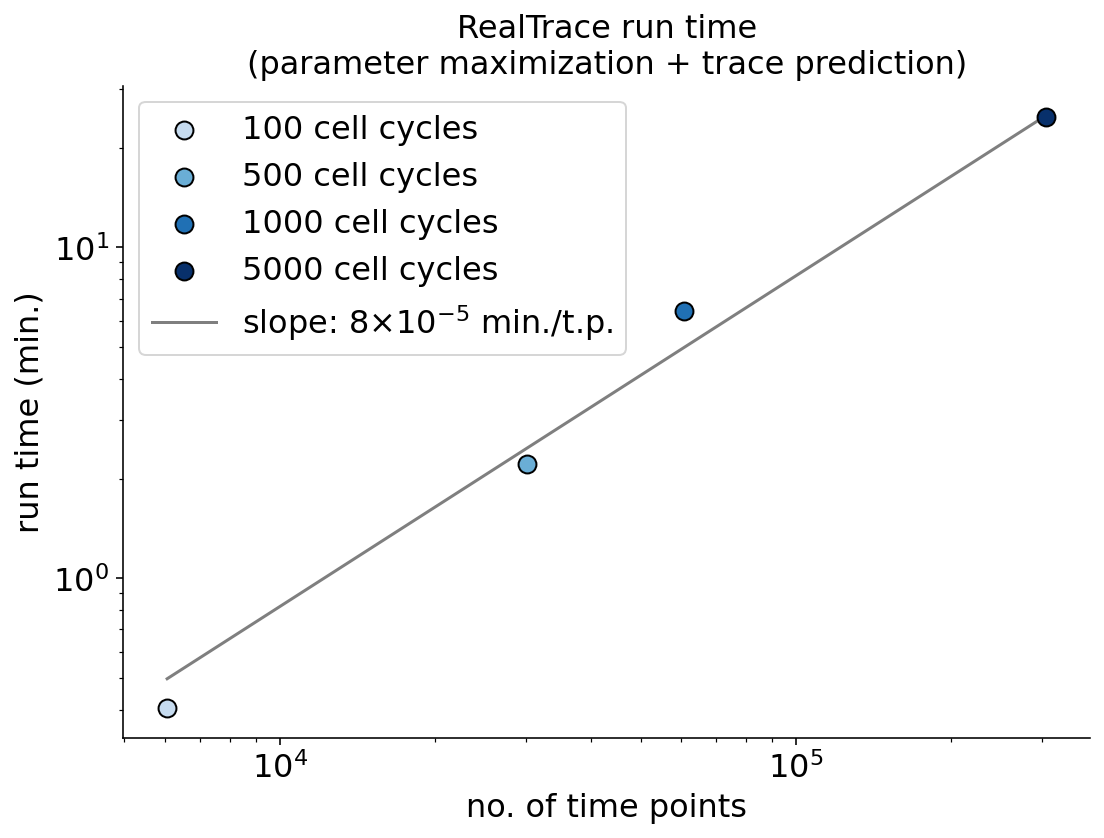

In [52]:
def lin_fit(x_, y_):
    x = np.array(x_)
    y = np.array(y_)
    # slope m = sum(x*y) / sum(x^2)
    m = (x*y).sum() / (x**2).sum()
    y_pred = m * x
    return m

def plot_runtime(n_cells, time_points, run_time, plot_file=None):
    fig, ax = plt.subplots(1,1, figsize=(FULL_SIZE/1.5,FULL_HEIGHT*1.5))

    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_xscale("log")
        a.set_yscale("log")

    run_time = np.array(run_time)/60
    cmap = matplotlib.cm.get_cmap('Blues')
    
    for i, _ in enumerate(n_cells):
        ax.scatter(time_points[i], run_time[i], 
                   s= 80, label=str(n_cells[i]) +" cell cycles", 
                  color=cmap((i+1)/len(n_cells)), 
                  ec="black")

    m =lin_fit(time_points, run_time)
    
    print(f"slope={m:.6f}")
    

    ax.plot( time_points, m*np.array(time_points),
           color="tab:grey", ls="-", zorder=-1, 
           label=r"slope: {:.0f}".format(m*1e5)+r"$\times10^{-5}$ min./t.p.")
        
    lg = ax.legend(ncol=1)
    # lg.set_title('no. of cell cycles',prop={'size':MEDIUM_SIZE})
    
    ax.set_xlabel("no. of time points")
    ax.set_ylabel("run time (min.)")

    ax.set_title("RealTrace run time\n(parameter maximization + trace prediction)")
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')
    plt.show()

n_cells = [100, 500, 1000, 5000]
time_points = [6053, 30130, 60794, 305578]
run_time = [24.274431208000003 , 132.683144291 , 385.0163507909999 , 1489.2483697089992 ]

plot_runtime(n_cells, time_points, run_time, plot_file=os.path.join("../../figures_for_method_paper/supp/", "run_time.pdf"))
